# Ліцей «Інтелект» Дарницького району м. Києва

м. Київ, проспект Миколи Бажана, 34-А. Назву й адресу взято з [довідника Управління освіти](https://druo.kyivcity.gov.ua/dovidnik-zakladiv/zzso/litsei-intelekt/page/1).

Сценарій 1 залікової роботи. Записи CSV про класи й учнів вигадані та призначені для демонстрації програми.


In [1]:
from collections import Counter, defaultdict
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from school import load_school


school = load_school(Path("."))
before = school.statistics()
display(pd.DataFrame(before, columns=["Показник до переведення", "Значення"]))

Показник до переведення,Значення
Усього учнів,288
Хлопці,43.06 %
Дівчата,56.94 %
Середня наповнюваність класу,13.71
Максимальна наповнюваність,"19 (4А, 7А)"
Мінімальна наповнюваність,8 (5Б)


## Розподіл учнів та оцінок

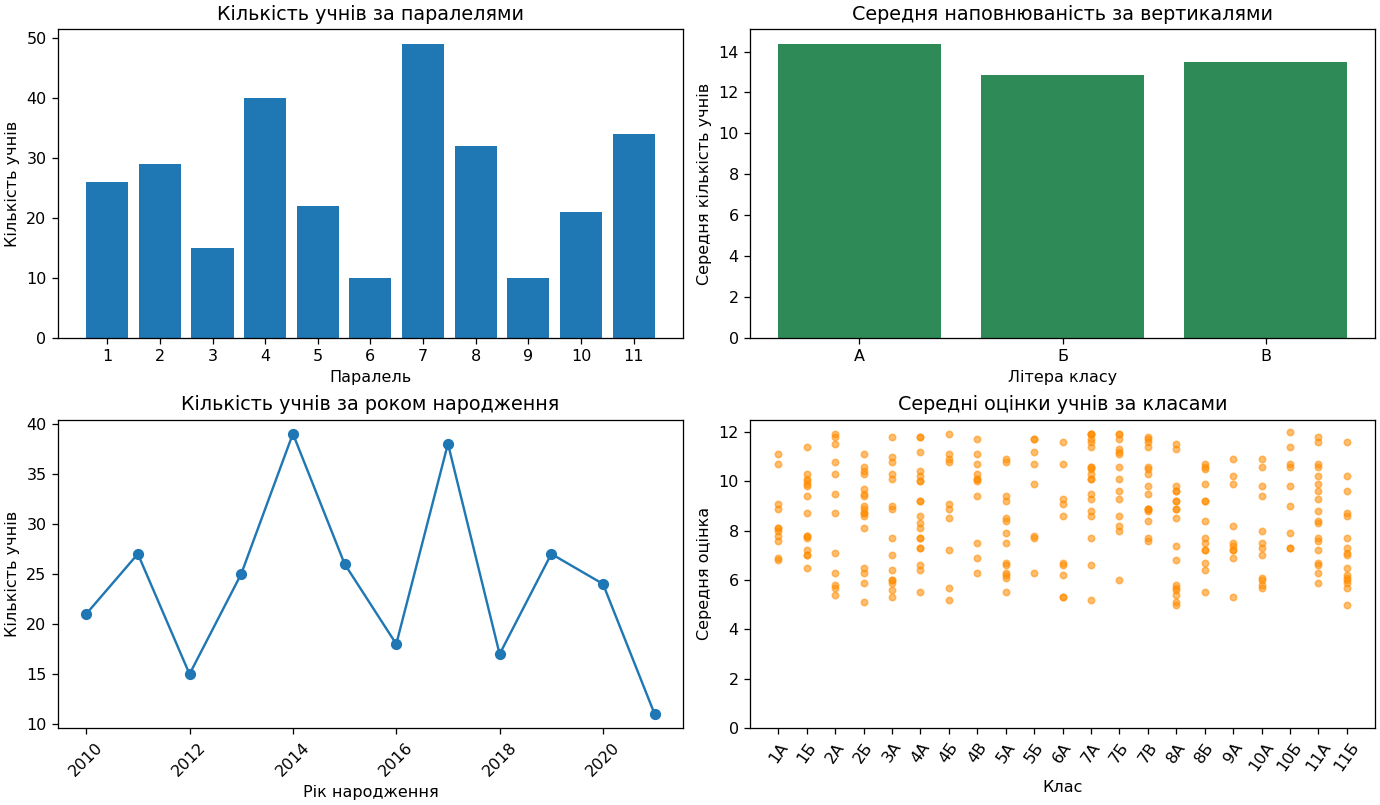

In [2]:
by_grade: Counter[int] = Counter()
by_letter: dict[str, list[int]] = defaultdict(list)
by_birth: Counter[int] = Counter()
class_positions: list[int] = []
marks: list[float] = []

for position, group in enumerate(school.classes):
    size = len(group.students)
    by_grade[group.grade] += size
    by_letter[group.letter].append(size)
    for student in group.students:
        by_birth[student.birth_year] += 1
        class_positions.append(position)
        marks.append(student.average_grade)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")

grades = sorted(by_grade)
axes[0, 0].bar(grades, [by_grade[grade] for grade in grades])
axes[0, 0].set(title="Кількість учнів за паралелями", xlabel="Паралель",
               ylabel="Кількість учнів", xticks=grades)

letters = sorted(by_letter)
axes[0, 1].bar(letters, [mean(by_letter[letter]) for letter in letters], color="seagreen")
axes[0, 1].set(title="Середня наповнюваність за вертикалями",
               xlabel="Літера класу", ylabel="Середня кількість учнів")

years = sorted(by_birth)
axes[1, 0].plot(years, [by_birth[year] for year in years], marker="o")
axes[1, 0].set(title="Кількість учнів за роком народження",
               xlabel="Рік народження", ylabel="Кількість учнів")
axes[1, 0].tick_params(axis="x", labelrotation=45)

axes[1, 1].scatter(class_positions, marks, s=16, alpha=0.55, color="darkorange")
axes[1, 1].set(title="Середні оцінки учнів за класами",
               xlabel="Клас", ylabel="Середня оцінка", ylim=(0, 12.5))
axes[1, 1].set_xticks(range(len(school.classes)),
                     [group.name for group in school.classes], rotation=55)
plt.show()

## Переведення класів

In [3]:
expected = {
    f"{group.grade + 1}{group.letter}": tuple(group.students)
    for group in school.classes
    if group.grade < 11
}
graduates = sum(len(group.students) for group in school.classes if group.grade == 11)
total_before = sum(len(group.students) for group in school.classes)

school.promote_classes()

assert {group.name: tuple(group.students) for group in school.classes} == expected
assert all(group.grade > 1 for group in school.classes)
assert sum(len(group.students) for group in school.classes) == total_before - graduates

print(f"Випустилося учнів: {graduates}")
print("Перевірено: 1 класу немає, склад переведених класів збігається.")
display(pd.DataFrame(school.statistics(), columns=["Показник після переведення", "Значення"]))

Випустилося учнів: 34
Перевірено: 1 класу немає, склад переведених класів збігається.


Показник після переведення,Значення
Усього учнів,254
Хлопці,43.31 %
Дівчата,56.69 %
Середня наповнюваність класу,13.37
Максимальна наповнюваність,"19 (5А, 8А)"
Мінімальна наповнюваність,8 (6Б)
